In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\samee\Desktop\Ultimate_Take_Home_Challenge
['.ipynb_checkpoints', 'Part1_Login_Analysis.ipynb', 'ultimate_challenge']


In [3]:
print(os.listdir("ultimate_challenge"))

['logins.json', 'ultimate_data_challenge.json', 'ultimate_data_science_challenge (1).pdf']


In [4]:
login_data = pd.read_json("ultimate_challenge/logins.json")

login_data.head()

,login_time
0,1970-01-01 20:13:18
1,1970-01-01 20:16:10
2,1970-01-01 20:16:37
3,1970-01-01 20:16:36
4,1970-01-01 20:26:21


In [5]:
print("Dataset information:")
login_data.info()

print("\nFirst 5 rows:")
display(login_data.head())

print("\nNumber of rows and columns:")
print(login_data.shape)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93142 entries, 0 to 93141
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   login_time  93142 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 727.8 KB

First 5 rows:


,login_time
0,1970-01-01 20:13:18
1,1970-01-01 20:16:10
2,1970-01-01 20:16:37
3,1970-01-01 20:16:36
4,1970-01-01 20:26:21



Number of rows and columns:
(93142, 1)


In [6]:
login_data = login_data.sort_values("login_time").reset_index(drop=True)

print("Earliest login:", login_data["login_time"].min())
print("Latest login:", login_data["login_time"].max())

print("Data sorted:", login_data["login_time"].is_monotonic_increasing)

Earliest login: 1970-01-01 20:12:16
Latest login: 1970-04-13 18:57:38
Data sorted: True


In [7]:
login_15min = (
    login_data
    .set_index("login_time")
    .resample("15min")
    .size()
    .reset_index(name="login_count")
)

display(login_15min.head(10))

,login_time,login_count
0,1970-01-01 20:00:00,2
1,1970-01-01 20:15:00,6
2,1970-01-01 20:30:00,9
3,1970-01-01 20:45:00,7
4,1970-01-01 21:00:00,1
5,1970-01-01 21:15:00,4
6,1970-01-01 21:30:00,0
7,1970-01-01 21:45:00,4
8,1970-01-01 22:00:00,9
9,1970-01-01 22:15:00,8


In [8]:
print("Total 15-minute intervals:", len(login_15min))
print("Total logins:", login_15min["login_count"].sum())

print("\nLogin count summary:")
display(login_15min["login_count"].describe())

Total 15-minute intervals: 9788
Total logins: 93142

Login count summary:


count    9788.000000
mean        9.515938
std         8.328818
min         0.000000
25%         3.000000
50%         7.000000
75%        13.000000
max        73.000000
Name: login_count, dtype: float64

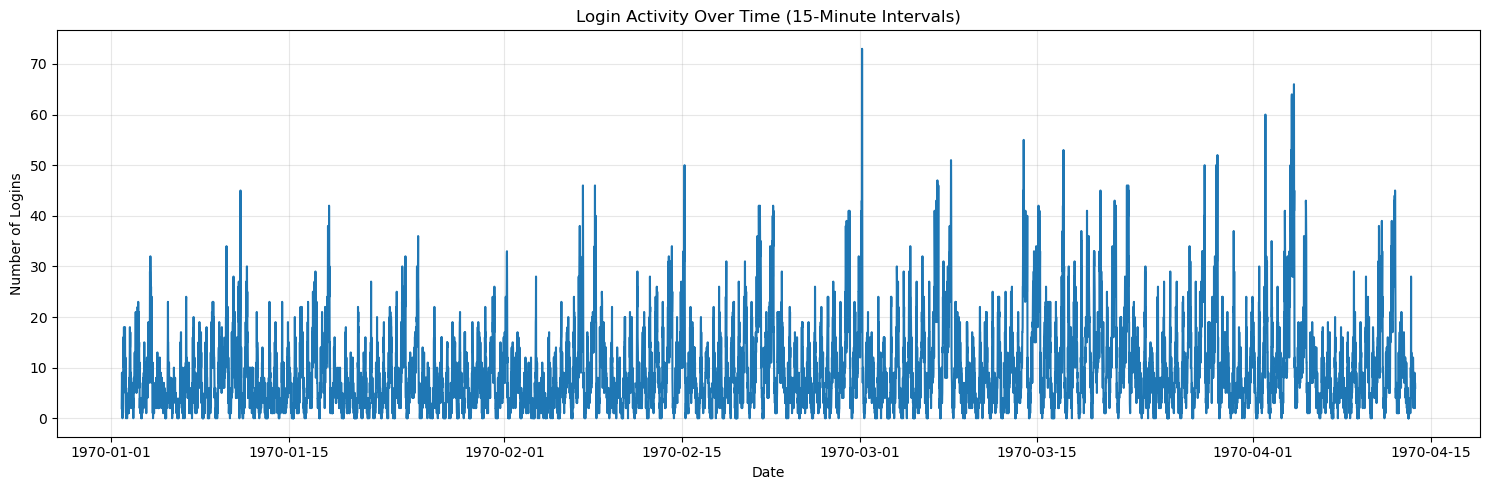

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(
    login_15min["login_time"],
    login_15min["login_count"]
)

plt.title("Login Activity Over Time (15-Minute Intervals)")
plt.xlabel("Date")
plt.ylabel("Number of Logins")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
login_15min["day_of_week"] = login_15min["login_time"].dt.day_name()

avg_logins_by_day = (
    login_15min.groupby("day_of_week")["login_count"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
)

display(avg_logins_by_day)

day_of_week
Monday        6.213380
Tuesday       6.895833
Wednesday     7.692708
Thursday      8.794118
Friday       10.561111
Saturday     13.456250
Sunday       12.615972
Name: login_count, dtype: float64

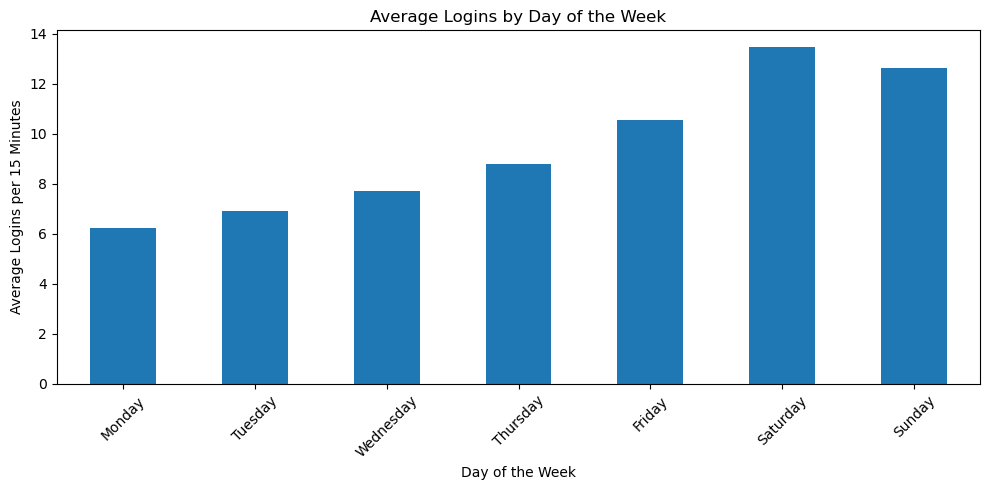

In [11]:
plt.figure(figsize=(10, 5))

avg_logins_by_day.plot(kind="bar")

plt.title("Average Logins by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Logins per 15 Minutes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
login_15min["hour"] = login_15min["login_time"].dt.hour

avg_logins_by_hour = (
    login_15min.groupby("hour")["login_count"]
    .mean()
)

display(avg_logins_by_hour)    

hour
0     14.688725
1     15.482843
2     14.215686
3     11.840686
4     12.338235
5      7.218137
6      2.789216
7      1.997549
8      2.004902
9      3.742647
10     7.509804
11    14.213235
12    12.166667
13     8.850490
14     8.397059
15     7.446078
16     6.941176
17     6.333333
18     7.303922
19     8.007426
20    10.056373
21    13.781863
22    16.193627
23    14.848039
Name: login_count, dtype: float64

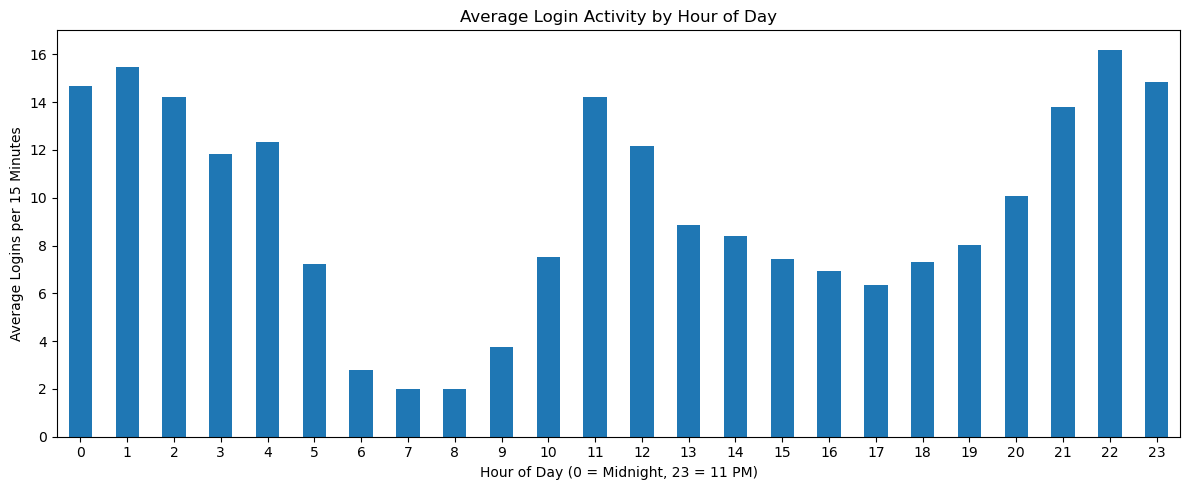

In [13]:
plt.figure(figsize=(12, 5))

avg_logins_by_hour.plot(kind="bar")

plt.title("Average Login Activity by Hour of Day")
plt.xlabel("Hour of Day (0 = Midnight, 23 = 11 PM)")
plt.ylabel("Average Logins per 15 Minutes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
print("Missing timestamps:", login_data["login_time"].isna().sum())

print("Duplicate timestamps:", login_data["login_time"].duplicated().sum())

print("Total login records:", len(login_data))

print("Negative login counts:", (login_15min["login_count"] < 0).sum())

print("Zero-login intervals:", (login_15min["login_count"] == 0).sum())

Missing timestamps: 0
Duplicate timestamps: 877
Total login records: 93142
Negative login counts: 0
Zero-login intervals: 407



# Part 1: Exploratory Data Analysis

## Objective
The objective of this analysis was to examine user login activity, aggregate login events into 15-minute intervals, identify temporal patterns, and check the dataset for potential data-quality issues.

## Dataset Overview
The dataset contained 93,142 login timestamps, covering January 1, 1970, through April 13, 1970. The timestamps were converted to datetime values and sorted chronologically before analysis.

## Login Activity Over Time
Login events were aggregated into 15-minute intervals. The aggregation produced 9,788 intervals, and the total number of logins remained 93,142, confirming that the aggregation preserved all login events.

The average number of logins per interval was approximately 9.52, with a median of 7 and a maximum of 73.

## Weekly Patterns
Average login activity increased toward the weekend. Saturday had the highest average, at approximately 13.46 logins per 15-minute interval, followed by Sunday at 12.62. Monday had the lowest average, at approximately 6.21.

## Hourly Patterns
Login activity varied by hour. The highest average occurred at hour 22 (10 PM), at approximately 16.19 logins per 15-minute interval. Activity was lowest around 7–8 AM, at approximately 2 logins per interval.

## Data Quality
There were no missing timestamps and no negative login counts. A total of 877 records shared timestamps with other records. These were retained because identical timestamps may represent legitimate separate login events.

The aggregation also contained 407 intervals with zero logins. These intervals were retained because they represent periods with no recorded activity.

## Conclusion
The analysis identified clear variations in login activity by day of the week and hour of the day. Activity was generally higher on weekends and late at night, while early mornings were quieter. These patterns may help inform operational planning and user-activity monitoring.

In [15]:
daily_logins = (
    login_data
    .set_index("login_time")
    .resample("D")
    .size()
)

print("Number of calendar days:", len(daily_logins))
print("\nDaily login summary:")
display(daily_logins.describe())

Number of calendar days: 103

Daily login summary:


count     103.000000
mean      904.291262
std       347.167463
min       112.000000
25%       643.000000
50%       827.000000
75%      1141.000000
max      1889.000000
dtype: float64

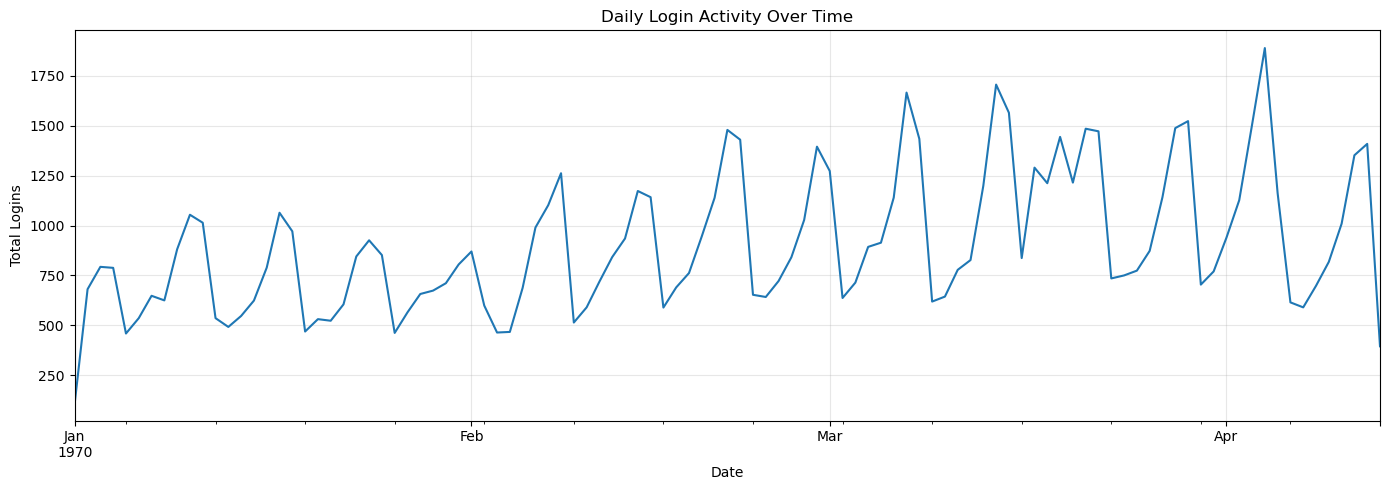

In [16]:
plt.figure(figsize=(14, 5))

daily_logins.plot()

plt.title("Daily Login Activity Over Time")
plt.xlabel("Date")
plt.ylabel("Total Logins")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Daily Login Activity

The dataset covers 103 calendar days. Daily login counts averaged approximately 904, with a median of 827. The minimum daily count was 112, while the maximum was 1,889. This variation indicates that user activity changes substantially from day to day.

A daily time-series visualization was created to examine fluctuations in activity over the observation period. The daily totals complement the 15-minute, hourly, and weekday analyses by showing variation at a broader time scale.

# Part 2: Experiment and Metrics Design

## 1. Key Measure of Success

I would choose the **percentage of driver partners who provide trips in both Gotham and Metropolis during the same measurement period** as the primary metric.

This metric directly measures whether toll reimbursement encourages drivers to work in both cities instead of remaining exclusive to one city. I would compare the percentage of drivers serving both cities in the group receiving toll reimbursement with the percentage in the control group that does not receive reimbursement.

I would also monitor supporting metrics, such as the number of trips completed in each city, driver availability during periods of high demand, rider wait times, and the total cost of toll reimbursements. These additional measures would help determine whether the experiment improves service availability in both cities at a reasonable cost.


### 2(a). Experiment Implementation

I would conduct a randomized controlled experiment to evaluate whether toll reimbursement encourages driver partners to serve both Gotham and Metropolis.

**1. Select participants:** I would recruit eligible driver partners who work in either city and are able to serve both cities.

**2. Create two groups:** I would randomly assign eligible drivers to one of two groups:

* **Treatment group:** Drivers receive reimbursement for toll costs when crossing the bridge.
* **Control group:** Drivers continue under the existing policy and do not receive toll reimbursement.

**3. Run the experiment:** I would run the experiment for approximately four to eight weeks to capture weekday and weekend patterns. Both groups would be observed over the same period.

**4. Measure outcomes:** I would compare the percentage of drivers who complete trips in both cities between the treatment and control groups. I would also track trip volume, driver availability, rider wait times, and reimbursement costs.

**5. Ensure a fair comparison:** Random assignment helps make the groups comparable. I would also examine whether drivers in both groups had similar activity levels before the experiment and account for any important differences.

This design would help estimate whether offering toll reimbursement causes an increase in drivers serving both cities.


### 2(b). Statistical Tests

I would use a **two-proportion z-test** to determine whether the percentage of drivers serving both Gotham and Metropolis is significantly different between the treatment and control groups.

* **Null hypothesis (H₀):** Toll reimbursement does not increase the proportion of drivers serving both cities.
* **Alternative hypothesis (H₁):** Toll reimbursement increases the proportion of drivers serving both cities.

I would use a significance level of 0.05. If the p-value is less than 0.05, I would reject the null hypothesis and conclude that there is statistically significant evidence of a difference in the primary metric. Because the goal is to increase cross-city service, I would also check whether the observed difference is positive.

I would report the difference in proportions and its 95% confidence interval, not just the p-value, to show the estimated size and uncertainty of the effect.

The two-proportion z-test assumes independent observations and an appropriate sample size. Because multiple drivers may be affected by shared conditions, I would also consider possible spillover between groups and other factors that could affect driver behavior.


### 2(c). Interpretation, Recommendations, and Caveats

**Interpreting the results**

If the treatment group has a higher proportion of drivers serving both cities than the control group, and the difference is statistically significant, this would provide evidence that toll reimbursement encourages cross-city service. I would also examine the size of the improvement and its 95% confidence interval to determine whether the effect is practically meaningful.

If the result is not statistically significant, I would not conclude that reimbursement has no effect. The experiment may need a larger sample or a longer measurement period to detect a meaningful improvement.

**Recommendations to the city operations team**

If reimbursement increases cross-city service and improves driver availability or reduces rider wait times at a reasonable cost, I would recommend considering a broader rollout. I would compare the additional benefits with the total reimbursement cost before making a final decision.

If the results are inconclusive, I would review the sample size, experiment duration, and driver participation before deciding whether to run another experiment. If reimbursement does not improve service sufficiently to justify its cost, I would not recommend implementing it in its current form.

**Caveats and limitations**

* Drivers may share information or influence one another, potentially affecting the results.
* Differences in demand, traffic, weather, and weekday versus weekend activity could influence driver behavior.
* A four-to-eight-week experiment may not capture longer-term changes in driver behavior.
* Statistical significance does not necessarily mean the improvement is large enough to justify the cost.
* The experiment should monitor rider wait times, service availability, reimbursement expenses, and any unintended effects on service in either city.

Overall, I would recommend making a decision based on the experiment's estimated impact, statistical uncertainty, operational benefits, and financial cost.


In [17]:
import pandas as pd

user_data = pd.read_json(
    "ultimate_challenge/ultimate_data_challenge.json"
)

print("Dataset loaded successfully!")
print("Dataset shape:", user_data.shape)

user_data.head()

Dataset loaded successfully!
Dataset shape: (50000, 12)


,city,trips_in_first_30_days,signup_date,avg_rating_of_driver,avg_surge,last_trip_date,phone,surge_pct,ultimate_black_user,weekday_pct,avg_dist,avg_rating_by_driver
0,King's Landing,4,2014-01-25,4.7,1.10,2014-06-17,iPhone,15.4,True,46.2,3.67,5.0
1,Astapor,0,2014-01-29,5.0,1.00,2014-05-05,Android,0.0,False,50.0,8.26,5.0
2,Astapor,3,2014-01-06,4.3,1.00,2014-01-07,iPhone,0.0,False,100.0,0.77,5.0
3,King's Landing,9,2014-01-10,4.6,1.14,2014-06-29,iPhone,20.0,True,80.0,2.36,4.9
4,Winterfell,14,2014-01-27,4.4,1.19,2014-03-15,Android,11.8,False,82.4,3.13,4.9


In [18]:
print("DATA TYPES:")
print(user_data.dtypes)

# Check missing values
print("\nMISSING VALUES:")
print(user_data.isnull().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS:")
print(user_data.duplicated().sum())

# Check date ranges
print("\nDATE RANGES:")
print("Earliest signup date:", user_data["signup_date"].min())
print("Latest signup date:", user_data["signup_date"].max())
print("Earliest last trip date:", user_data["last_trip_date"].min())
print("Latest last trip date:", user_data["last_trip_date"].max())

DATA TYPES:
city                       object
trips_in_first_30_days      int64
signup_date                object
avg_rating_of_driver      float64
avg_surge                 float64
last_trip_date             object
phone                      object
surge_pct                 float64
ultimate_black_user          bool
weekday_pct               float64
avg_dist                  float64
avg_rating_by_driver      float64
dtype: object

MISSING VALUES:
city                         0
trips_in_first_30_days       0
signup_date                  0
avg_rating_of_driver      8122
avg_surge                    0
last_trip_date               0
phone                      396
surge_pct                    0
ultimate_black_user          0
weekday_pct                  0
avg_dist                     0
avg_rating_by_driver       201
dtype: int64

DUPLICATE ROWS:
8

DATE RANGES:
Earliest signup date: 2014-01-01
Latest signup date: 2014-01-31
Earliest last trip date: 2014-01-01
Latest last trip date: 2014-07-

In [19]:
# Convert date columns to datetime
user_data["signup_date"] = pd.to_datetime(user_data["signup_date"])
user_data["last_trip_date"] = pd.to_datetime(user_data["last_trip_date"])

# Define the observation date and retention cutoff
observation_date = user_data["last_trip_date"].max()
retention_cutoff = observation_date - pd.Timedelta(days=30)

# Create the retention target
user_data["retained"] = (
    user_data["last_trip_date"] >= retention_cutoff
)

# Calculate retention statistics
retained_count = user_data["retained"].sum()
total_users = len(user_data)
retention_rate = user_data["retained"].mean()

print("Observation date:", observation_date.date())
print("Retention cutoff:", retention_cutoff.date())
print("Total users:", total_users)
print("Retained users:", retained_count)
print("Not retained users:", total_users - retained_count)
print(f"Retention rate: {retention_rate:.2%}")

Observation date: 2014-07-01
Retention cutoff: 2014-06-01
Total users: 50000
Retained users: 18804
Not retained users: 31196
Retention rate: 37.61%


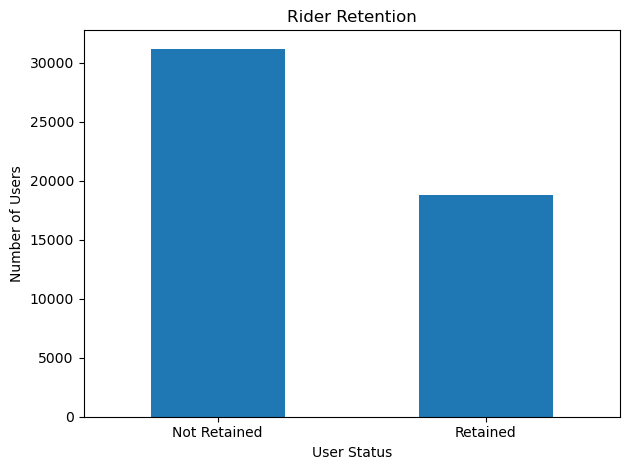

In [20]:
import matplotlib.pyplot as plt

retention_counts = user_data["retained"].value_counts().sort_index()

retention_counts.index = ["Not Retained", "Retained"]

retention_counts.plot(kind="bar")

plt.title("Rider Retention")
plt.xlabel("User Status")
plt.ylabel("Number of Users")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Retention rate by city:
city
King's Landing    62.81
Winterfell        35.19
Astapor           25.57
Name: retained, dtype: float64


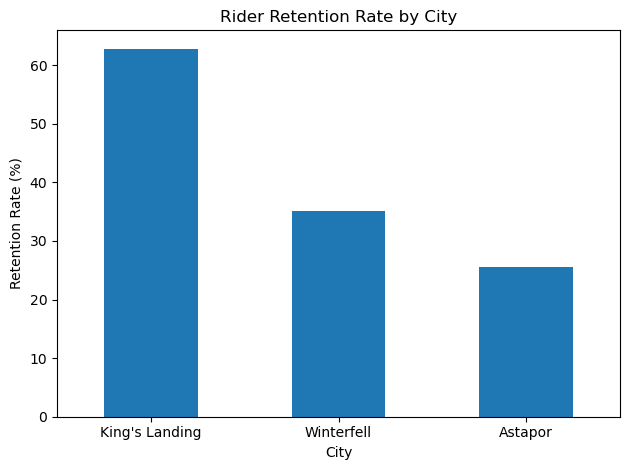

In [21]:
# Calculate retention rate for each city
city_retention = user_data.groupby("city")["retained"].mean() * 100

# Display the results
print("Retention rate by city:")
print(city_retention.sort_values(ascending=False).round(2))

# Visualize the results
city_retention.sort_values(ascending=False).plot(kind="bar")

plt.title("Rider Retention Rate by City")
plt.xlabel("City")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Retention rate by phone type:
phone
Android    20.94
iPhone     44.89
Name: retained, dtype: float64


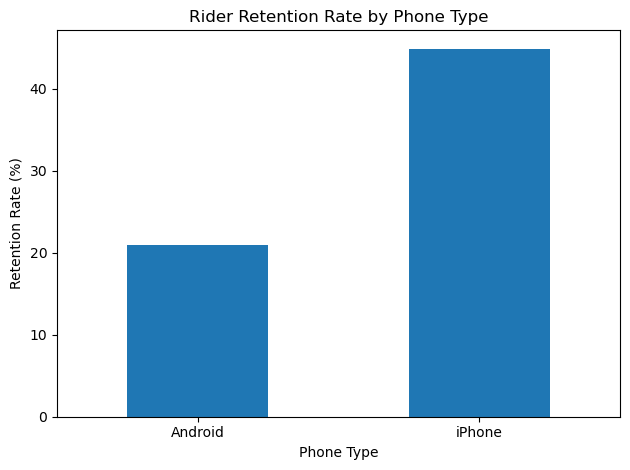

In [22]:
# Calculate retention rate by phone type
phone_retention = user_data.groupby("phone")["retained"].mean() * 100

print("Retention rate by phone type:")
print(phone_retention.round(2))

# Visualize the results
phone_retention.plot(kind="bar")

plt.title("Rider Retention Rate by Phone Type")
plt.xlabel("Phone Type")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Retention rate by first-30-day trip group:
trip_group
0 trips      36.26
1–2 trips    27.28
3–5 trips    49.36
6+ trips     66.69
Name: retained, dtype: float64


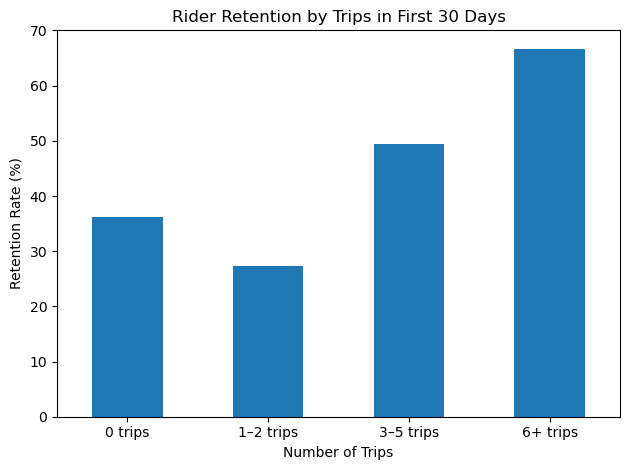

In [23]:
# Group users by number of trips in their first 30 days
user_data["trip_group"] = pd.cut(
    user_data["trips_in_first_30_days"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=["0 trips", "1–2 trips", "3–5 trips", "6+ trips"]
)

# Calculate retention rate for each group
trip_retention = user_data.groupby(
    "trip_group", observed=False
)["retained"].mean() * 100

print("Retention rate by first-30-day trip group:")
print(trip_retention.round(2))

# Visualize the results
trip_retention.plot(kind="bar")

plt.title("Rider Retention by Trips in First 30 Days")
plt.xlabel("Number of Trips")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Retention rate by Ultimate Black usage:
Not Ultimate Black    29.88
Ultimate Black        50.37
Name: retained, dtype: float64


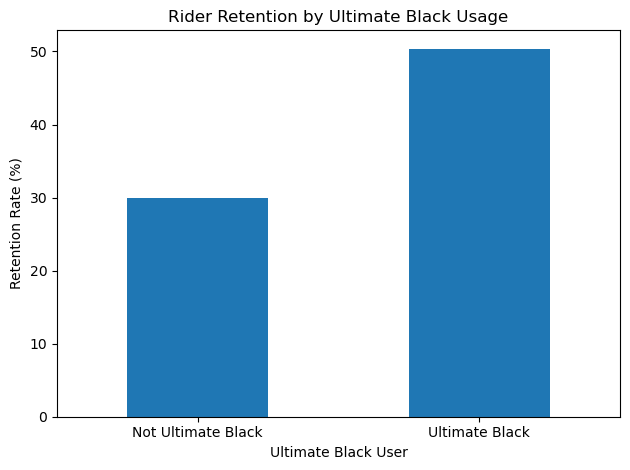

In [24]:
# Calculate retention rate by Ultimate Black usage
black_retention = user_data.groupby(
    "ultimate_black_user"
)["retained"].mean() * 100

black_retention.index = ["Not Ultimate Black", "Ultimate Black"]

print("Retention rate by Ultimate Black usage:")
print(black_retention.round(2))

# Visualize the results
black_retention.plot(kind="bar")

plt.title("Rider Retention by Ultimate Black Usage")
plt.xlabel("Ultimate Black User")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Average trips in first 30 days:
Not Retained    1.66
Retained        3.31
Name: trips_in_first_30_days, dtype: float64


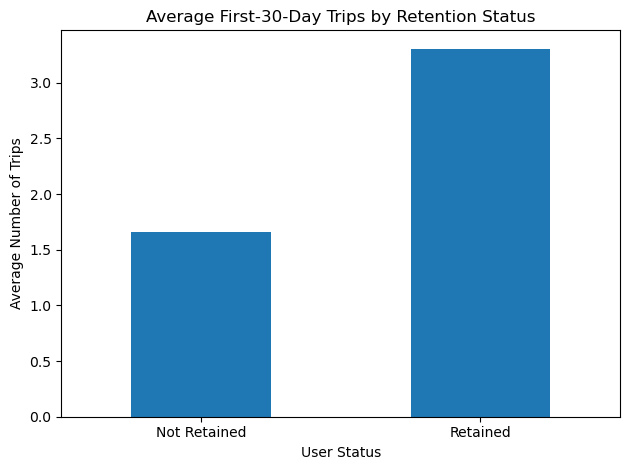

In [25]:
# Compare average early trips by retention status
avg_trips = user_data.groupby("retained")[
    "trips_in_first_30_days"
].mean()

avg_trips.index = ["Not Retained", "Retained"]

print("Average trips in first 30 days:")
print(avg_trips.round(2))

# Visualize the results
avg_trips.plot(kind="bar")

plt.title("Average First-30-Day Trips by Retention Status")
plt.xlabel("User Status")
plt.ylabel("Average Number of Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
# Remove the exploratory grouping column
user_data = user_data.drop(columns=["trip_group"])

# Check missing values in the original predictor columns
print("Missing values:")
print(user_data.isnull().sum())

# Confirm the retention target
print("\nRetention target:")
print(user_data["retained"].value_counts())

# Check the dataset shape
print("\nDataset shape:", user_data.shape)

Missing values:
city                         0
trips_in_first_30_days       0
signup_date                  0
avg_rating_of_driver      8122
avg_surge                    0
last_trip_date               0
phone                      396
surge_pct                    0
ultimate_black_user          0
weekday_pct                  0
avg_dist                     0
avg_rating_by_driver       201
retained                     0
dtype: int64

Retention target:
retained
False    31196
True     18804
Name: count, dtype: int64

Dataset shape: (50000, 13)


In [27]:
# Define the target
y = user_data["retained"]

# Define the predictors
X = user_data.drop(
    columns=["retained", "last_trip_date", "signup_date"]
)

print("Predictor dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nPredictor columns:")
print(X.columns.tolist())

Predictor dataset shape: (50000, 10)
Target dataset shape: (50000,)

Predictor columns:
['city', 'trips_in_first_30_days', 'avg_rating_of_driver', 'avg_surge', 'phone', 'surge_pct', 'ultimate_black_user', 'weekday_pct', 'avg_dist', 'avg_rating_by_driver']


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("\nTraining retention rates:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting retention rates:")
print(y_test.value_counts(normalize=True).round(3))

Training predictors: (40000, 10)
Testing predictors: (10000, 10)

Training retention rates:
retained
False    0.624
True     0.376
Name: proportion, dtype: float64

Testing retention rates:
retained
False    0.624
True     0.376
Name: proportion, dtype: float64


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Separate numeric and categorical columns
numeric_features = [
    "trips_in_first_30_days",
    "avg_rating_of_driver",
    "avg_surge",
    "surge_pct",
    "weekday_pct",
    "avg_dist",
    "avg_rating_by_driver"
]

categorical_features = [
    "city",
    "phone",
    "ultimate_black_user"
]

# Prepare numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

print("Preprocessing pipeline and Logistic Regression model created.")

Preprocessing pipeline and Logistic Regression model created.


In [30]:
logistic_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [31]:
# Predict retention for the test users
y_pred = logistic_model.predict(X_test)

# Predict the probability of retention
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")
print("\nFirst 10 predicted outcomes:")
print(y_pred[:10])

print("\nFirst 10 actual outcomes:")
print(y_test.iloc[:10].to_numpy())

Predictions completed successfully!

First 10 predicted outcomes:
[False  True False False  True False False  True False False]

First 10 actual outcomes:
[ True  True  True False  True False False  True False False]


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Calculate performance metrics
print("MODEL PERFORMANCE")
print("------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

MODEL PERFORMANCE
------------------
Accuracy:  0.7148
Precision: 0.6635
Recall:    0.4903
F1-score:  0.5639
ROC-AUC:   0.7537

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       False       0.73      0.85      0.79      6239
        True       0.66      0.49      0.56      3761

    accuracy                           0.71     10000
   macro avg       0.70      0.67      0.68     10000
weighted avg       0.71      0.71      0.70     10000

CONFUSION MATRIX
[[5304  935]
 [1917 1844]]


In [33]:
from sklearn.ensemble import RandomForestClassifier

In [34]:
# Create a Random Forest model using the same preprocessing
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions
rf_pred = random_forest_model.predict(X_test)
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("RANDOM FOREST PERFORMANCE")
print("-------------------------")
print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.4f}")
print(f"Precision: {precision_score(y_test, rf_pred):.4f}")
print(f"Recall:    {recall_score(y_test, rf_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, rf_prob):.4f}")

RANDOM FOREST PERFORMANCE
-------------------------
Accuracy:  0.7759
Precision: 0.6917
Recall:    0.7291
F1-score:  0.7099
ROC-AUC:   0.8504


TOP 10 IMPORTANT FEATURES:
                    feature  importance
  num__avg_rating_by_driver    0.145541
              num__avg_dist    0.139587
           num__weekday_pct    0.138229
             num__surge_pct    0.092341
   cat__city_King's Landing    0.090263
num__trips_in_first_30_days    0.081604
             num__avg_surge    0.077303
  num__avg_rating_of_driver    0.056612
         cat__phone_Android    0.037678
          cat__phone_iPhone    0.037653


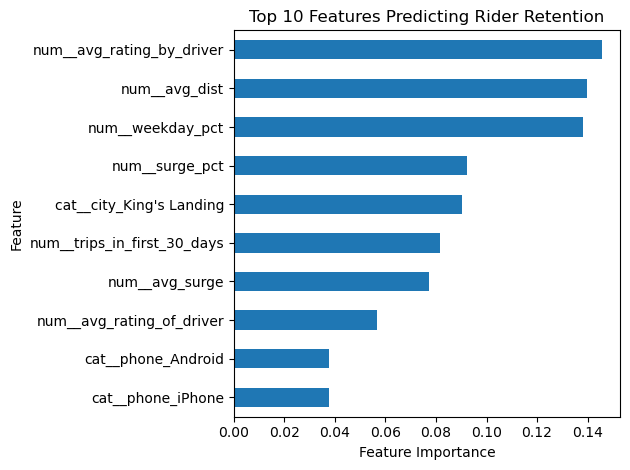

In [35]:
# Get the trained preprocessing and Random Forest classifier
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance scores
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

# Show the 10 most important features
top_features = feature_importance.sort_values(
    by="importance",
    ascending=False
).head(10)

print("TOP 10 IMPORTANT FEATURES:")
print(top_features.to_string(index=False))

# Visualize the results
top_features.sort_values("importance").plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False
)

plt.title("Top 10 Features Predicting Rider Retention")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [36]:
print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(y_test, rf_pred))

print("RANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

       False       0.83      0.80      0.82      6239
        True       0.69      0.73      0.71      3761

    accuracy                           0.78     10000
   macro avg       0.76      0.77      0.76     10000
weighted avg       0.78      0.78      0.78     10000

RANDOM FOREST CONFUSION MATRIX
[[5017 1222]
 [1019 2742]]


## Part 3: Predictive Modeling — Findings and Recommendations.

# Part 3: Predictive Modeling

## 1. Data Cleaning, Exploratory Analysis, and Retention Rate

The dataset contained 50,000 users and 12 original columns. I inspected data types, missing values, duplicate records, and date ranges. The `avg_rating_of_driver` column contained 8,122 missing values, `phone` contained 396, and `avg_rating_by_driver` contained 201. I retained users with missing values and handled them through a preprocessing pipeline: median imputation for numerical variables and most-frequent-value imputation for categorical variables. I converted the date columns to datetime format and identified eight duplicate rows. I flagged these rows for review rather than automatically removing them, since identical records should be investigated before deciding whether they are erroneous.

I defined a user as retained if their last trip occurred within 30 days of the latest recorded trip date, July 1, 2014. This gave a retention cutoff of June 1, 2014. Under this definition, 18,804 of the 50,000 users were retained, resulting in a **retention rate of 37.61%**.

Exploratory analysis showed differences in retention across cities and user behaviors. King's Landing had the highest retention rate (62.81%), followed by Winterfell (35.19%) and Astapor (25.57%). iPhone users had a retention rate of 44.89%, compared with 20.94% for Android users. Users who took six or more trips in their first 30 days had a retention rate of 66.69%. Retained users also averaged 3.31 trips in their first 30 days, compared with 1.66 trips among non-retained users. These findings indicate associations with retention but do not establish causation.

## 2. Predictive Modeling and Model Evaluation

I built a Logistic Regression model as a baseline and compared it with a Random Forest classifier. I excluded `last_trip_date` because it was used to define the retention target, preventing target leakage. I also excluded `signup_date` because all users signed up during January 2014. The remaining 10 predictors included city, phone type, early trip activity, ratings, trip distance, surge pricing, weekday trip percentage, and Ultimate Black usage.

I split the data into 80% training data (40,000 users) and 20% testing data (10,000 users), using stratification to preserve the retention distribution. I used a preprocessing pipeline to handle missing values, scale numerical features, and one-hot encode categorical features.

The Logistic Regression model achieved 71.48% accuracy, a 56.39% F1-score for retained users, and a ROC-AUC of 0.7537. The Random Forest model performed better, achieving **77.59% accuracy, a 70.99% F1-score for retained users, and a ROC-AUC of 0.8504**. Its recall for retained users was 72.91%, meaning it correctly identified approximately 73% of the retained users in the test set.

I selected Random Forest as the leading model because it performed better across all five measured metrics and can capture nonlinear relationships. Its most important features were average rating by driver, average trip distance, weekday trip percentage, surge percentage, and city membership in King's Landing. Feature importance indicates which features the model relied on most; it does not establish causation or indicate that changing a feature will necessarily improve retention.

The results are promising but have limitations. The model was evaluated on one random train/test split, so cross-validation and additional validation would help assess reliability. Some predictors, such as ratings, may be missing for users with limited activity. The dataset represents a specific cohort and period, so performance may change over time or in other markets. The classification threshold could also be adjusted depending on whether Ultimate prioritizes identifying more retained users or limiting unnecessary outreach. Further validation and threshold analysis are recommended before operational deployment.

## 3. Recommendations to Improve Long-Term Rider Retention

Ultimate should investigate early rider engagement, rider experience, pricing, and differences between cities. Potential initiatives include encouraging repeat trips during the first 30 days, investigating factors associated with rider ratings, reviewing how surge pricing relates to rider behavior, and studying why retention is higher in King's Landing.

The company could use the model to prioritize retention outreach and test targeted offers or engagement campaigns through controlled experiments. Campaign effectiveness should be measured by incremental improvements in retention and cost-effectiveness rather than assuming that model predictions alone will improve retention. Ultimate should compare campaign results with a control group before deciding whether to expand successful initiatives.
